In [ ]:
#Import libraries

import pandas as pd
import numpy as np
import os
import warnings
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.impute import SimpleImputer

# Regression models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')

# 1. Initialize Repository Folder Structure
directories = [
    'data/raw',
    'data/processed',
    'notebooks',
    'src',
    'models',
    'logs',
    'outputs',
    'configs',
    'reports'
]
for directory in directories:
    os.makedirs(directory, exist_ok=True)
    
print("Project directory structure initialized!")

we import required libraries because python doesnt have all the functions needed for this ML project by default

pandas - used to load and work with the dataset
numpy - used for numerical calculations
matplotlib - used to create graphs
scikit learn - used for splitting the data, preprocessing, building regression models,model evaluation

In [93]:
#load the dataset
df = pd.read_csv("C:\\Users\\jayan\\Downloads\\flavors_of_cacao.csv")


The chocolate bar ratings dataset is loaded using pandas 
Can access and work with the data by loading the dataset

In [94]:
print("First 5 rows:")
print(df.head())

First 5 rows:
  Company \n(Maker-if known) Specific Bean Origin\nor Bar Name   REF  \
0                   A. Morin                       Agua Grande  1876   
1                   A. Morin                             Kpime  1676   
2                   A. Morin                            Atsane  1676   
3                   A. Morin                             Akata  1680   
4                   A. Morin                            Quilla  1704   

   Review\nDate Cocoa\nPercent Company\nLocation  Rating Bean\nType  \
0          2016            63%            France    3.75              
1          2015            70%            France    2.75              
2          2015            70%            France    3.00              
3          2015            70%            France    3.50              
4          2015            70%            France    3.50              

  Broad Bean\nOrigin  
0           Sao Tome  
1               Togo  
2               Togo  
3               Togo  
4          

displays the first 5 rows by using df.head to get an idea of how the data looks like

In [95]:
print("\nShape of dataset:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())


Shape of dataset:
(1795, 9)

Column names:
['Company\xa0\n(Maker-if known)', 'Specific Bean Origin\nor Bar Name', 'REF', 'Review\nDate', 'Cocoa\nPercent', 'Company\nLocation', 'Rating', 'Bean\nType', 'Broad Bean\nOrigin']


df.shape - gives (no. of rows, no. of cols)
df.columns - gets the column names in pandas index(used to store col names)
.tolist() - convert pandas data into python list 

In [96]:
#Clean Col Names
df.columns = (
    df.columns
    .str.replace("\xa0", " ", regex=False)
    .str.replace("\n", " ", regex=False)
    .str.strip()
)

print("\nCleaned column names:")
print(df.columns.tolist())


Cleaned column names:
['Company  (Maker-if known)', 'Specific Bean Origin or Bar Name', 'REF', 'Review Date', 'Cocoa Percent', 'Company Location', 'Rating', 'Bean Type', 'Broad Bean Origin']


data contains unwanted characters such as non-breaking spaces(\xa0), newline characters(\n), or extra spaces.
so replace non-breaking spaces and newline characters with normal spaces 
strip() - to remove unnecessary spaces from the beginning and end of the column names

In [97]:
print("\nDataset Information:")
print(df.info())



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1795 entries, 0 to 1794
Data columns (total 9 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Company  (Maker-if known)         1795 non-null   str    
 1   Specific Bean Origin or Bar Name  1795 non-null   str    
 2   REF                               1795 non-null   int64  
 3   Review Date                       1795 non-null   int64  
 4   Cocoa Percent                     1795 non-null   str    
 5   Company Location                  1795 non-null   str    
 6   Rating                            1795 non-null   float64
 7   Bean Type                         1794 non-null   str    
 8   Broad Bean Origin                 1794 non-null   str    
dtypes: float64(1), int64(2), str(6)
memory usage: 126.3 KB
None


info() - used to understand the basic structure of the dataset
provides information about : the number of records, col names, data types, no. of non-null values in each column

In [98]:
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values:
Company  (Maker-if known)           0
Specific Bean Origin or Bar Name    0
REF                                 0
Review Date                         0
Cocoa Percent                       0
Company Location                    0
Rating                              0
Bean Type                           1
Broad Bean Origin                   1
dtype: int64

Duplicate Rows:
0


isnull() - identifies missing values
sum() - counts them for each column
duplicated() - checks whether the same complete row appears more than once.

In [99]:
#removing duplicates
df = df.drop_duplicates()

print("\nShape after removing duplicates:")
print(df.shape)



Shape after removing duplicates:
(1795, 9)


drop_duplicates() -used to remove duplicate records
bcoz duplicate data can cause certain observations to be counted more than once and may affect the performance of the machine learning model
After removing the duplicates we use df.shape to check the updated number of rows and columns to verify


In [100]:
#Cleaning %
print("Before cleaning:")
print(df["Cocoa Percent"].head(5))
if "Cocoa Percent" in df.columns:
    df["Cocoa Percent"] = (
        df["Cocoa Percent"]
        .astype(str)
        .str.replace("%", "", regex=False)
    )

    df["Cocoa Percent"] = pd.to_numeric(
        df["Cocoa Percent"], errors="coerce"
    )
    print("After cleaning:")
print(df["Cocoa Percent"].head(5))

Before cleaning:
0    63%
1    70%
2    70%
3    70%
4    70%
Name: Cocoa Percent, dtype: str
After cleaning:
0    63.0
1    70.0
2    70.0
3    70.0
4    70.0
Name: Cocoa Percent, dtype: float64


the Cocoa Percent column contains % symbol such as 70% or 85% which is text values
so first we remove % by replacing "%" with ""
pd.to_numeric() - used to convert the values into numeric data
errors="coerce" - this parameter converts any invalid values into NaN

               Cocoa Percent  Review Date       REF    Rating
Cocoa Percent       1.000000     0.038177  0.037791 -0.164820
Review Date         0.038177     1.000000  0.985076  0.099846
REF                 0.037791     0.985076  1.000000  0.101030
Rating             -0.164820     0.099846  0.101030  1.000000


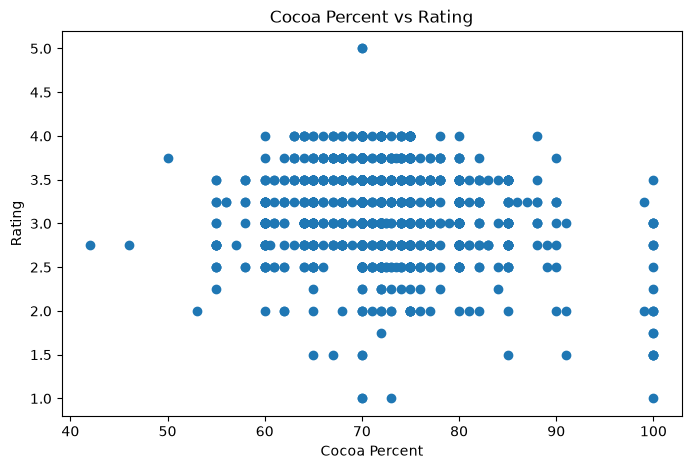

In [101]:
print(
    df[["Cocoa Percent", "Review Date", "REF", "Rating"]].corr()
)
plt.figure(figsize=(8, 5))
plt.scatter(df["Cocoa Percent"], df["Rating"])
plt.xlabel("Cocoa Percent")
plt.ylabel("Rating")
plt.title("Cocoa Percent vs Rating")
plt.show()

In [102]:
#CHECK TARGET VARIABLE
print("\nRating statistics:")
print(df["Rating"].describe())


Rating statistics:
count    1795.000000
mean        3.185933
std         0.478062
min         1.000000
25%         2.875000
50%         3.250000
75%         3.500000
max         5.000000
Name: Rating, dtype: float64


describe() - provides statistical information such as the count, mean, standard deviation, minimum, maximum, and quartile values of the ratings

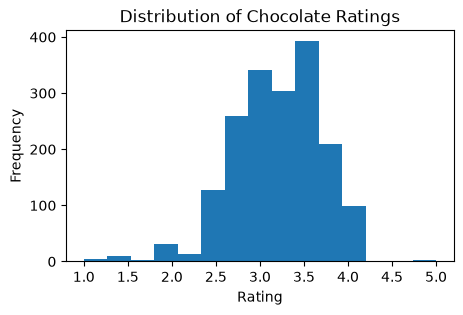

In [103]:
#VISUALIZATION FOR RATINGS
plt.figure(figsize=(5, 3))
plt.hist(df["Rating"], bins=15)
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.title("Distribution of Chocolate Ratings")
plt.show()

figsize=(8,5) - sets the graph size
plt.hist() - creates the histogram
df["Rating"] - uses Rating as the variable
bins=15 - divides ratings into 15 groups/intervals
xlabel() - labels the X-axis as Rating
ylabel() - labels the Y-axis as Frequency
title() - gives the graph a title
show() - displays the graph

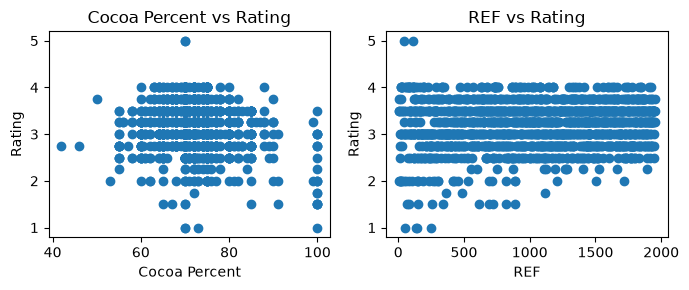


Numerical Correlation:
               Cocoa Percent  Review Date       REF    Rating
Cocoa Percent       1.000000     0.038177  0.037791 -0.164820
Review Date         0.038177     1.000000  0.985076  0.099846
REF                 0.037791     0.985076  1.000000  0.101030
Rating             -0.164820     0.099846  0.101030  1.000000


In [104]:
# NUMERICAL FEATURES EDA
plt.figure(figsize=(7, 3))

# Cocoa Percent vs Rating
plt.subplot(1, 2, 1)
plt.scatter(df["Cocoa Percent"], df["Rating"])
plt.xlabel("Cocoa Percent")
plt.ylabel("Rating")
plt.title("Cocoa Percent vs Rating")

# REF vs Rating
plt.subplot(1, 2, 2)
plt.scatter(df["REF"], df["Rating"])
plt.xlabel("REF")
plt.ylabel("Rating")
plt.title("REF vs Rating")

plt.tight_layout()
plt.show()

# Correlation
print("\nNumerical Correlation:")
print(df[["Cocoa Percent", "Review Date", "REF", "Rating"]].corr())

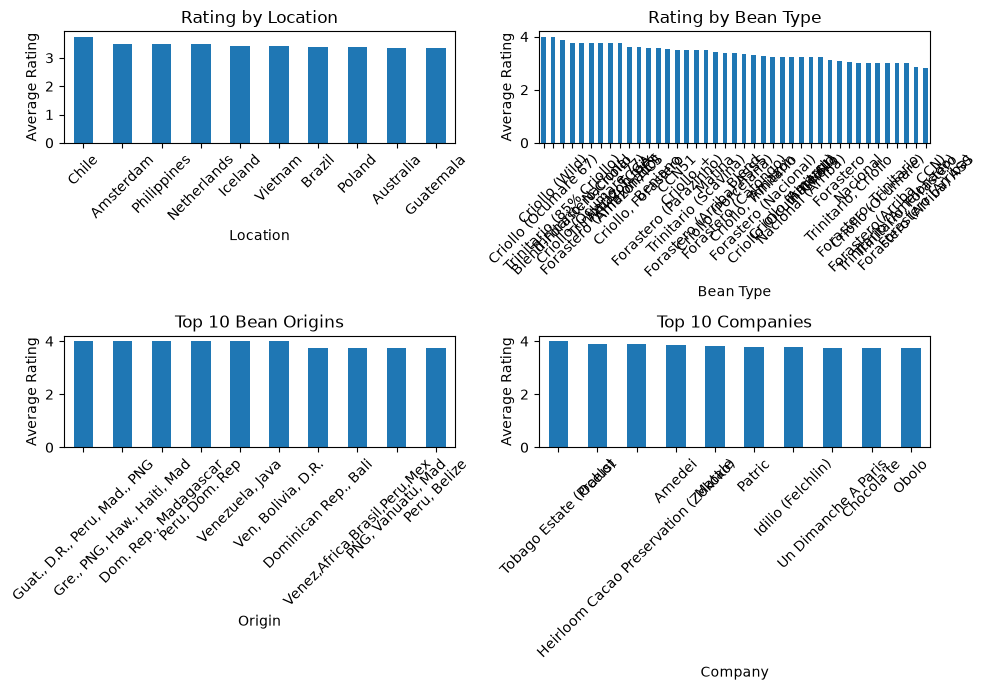

In [105]:
# ==============================
# CATEGORICAL FEATURES EDA
# ==============================

plt.figure(figsize=(10, 7))

# Company Location
plt.subplot(2, 2, 1)

location_rating = (
    df.groupby("Company Location")["Rating"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

location_rating.plot(kind="bar")
plt.xlabel("Location")
plt.ylabel("Average Rating")
plt.title("Rating by Location")
plt.xticks(rotation=45)

# Bean Type
plt.subplot(2, 2, 2)

bean_rating = (
    df.groupby("Bean Type")["Rating"]
      .mean()
      .sort_values(ascending=False)
)

bean_rating.plot(kind="bar")
plt.xlabel("Bean Type")
plt.ylabel("Average Rating")
plt.title("Rating by Bean Type")
plt.xticks(rotation=45)

# Broad Bean Origin
plt.subplot(2, 2, 3)

origin_rating = (
    df.groupby("Broad Bean Origin")["Rating"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

origin_rating.plot(kind="bar")
plt.xlabel("Origin")
plt.ylabel("Average Rating")
plt.title("Top 10 Bean Origins")
plt.xticks(rotation=45)

# Company
plt.subplot(2, 2, 4)

company_rating = (
    df.groupby("Company  (Maker-if known)")["Rating"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

company_rating.plot(kind="bar")
plt.xlabel("Company")
plt.ylabel("Average Rating")
plt.title("Top 10 Companies")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [106]:
#DEFINE FEATURES AND TARGET
X = df.drop("Rating", axis=1)
y = df["Rating"]

X - contains all the input features that will be used by the machine learning models to make predictions
y - contains the Rating column which is the value we want to predict
.drop - removes smthg from the dataset
axis=1 - tells that Rating is a column not a row

In [107]:
#REMOVE UNNECESSARY ID-LIKE COLUMN
print("Before Dropping:")
print(X.shape)
if "REF" in X.columns:
    X = X.drop("REF", axis=1)
print("After Dropping:")
print(X.shape)

Before Dropping:
(1795, 8)
After Dropping:
(1795, 7)


we remove the REF column from the feature set because it is only a reference or identification number
It does not provide meaningful information about the chocolate or its rating
So we remove unnecessary cols to prevent irrelevant information from affecting the regression models

X.columns - names of all feature columns
if REF found then we drop it

In [108]:
# IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
print("\nNumerical Features:")
print(numeric_features)
print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['Review Date', 'Cocoa Percent']

Categorical Features:
['Company  (Maker-if known)', 'Specific Bean Origin or Bar Name', 'Company Location', 'Bean Type', 'Broad Bean Origin']


C:\Users\jayan\AppData\Local\Temp\ipykernel_6544\506896054.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


select_dtypes() - A Pandas function used to select columns based on their data type
int64 / float64 - Numerical data types
object - represents text/categorical data
tolist() - Converts the column names into a Python list

here we divide features into 2 categories : numerical and categorical because numerical and categorical features require different preprocessing techniques

In [109]:
# Handle missing numerical values
for col in numeric_features:
    X[col] = X[col].fillna(X[col].median())

# Handle missing categorical values
for col in categorical_features:
    X[col] = X[col].fillna(X[col].mode()[0])


fillna() - used to replace missing values
for numerical: we use median bcoz it is less affected by extreme values or outliers
X[col].median() - calculates the median of that particular numerical column 
for categorical: 
mode() - finds the value that occurs most frequently.

In [110]:
print("\nMissing Values After Preprocessing:")
print(X.isnull().sum())


Missing Values After Preprocessing:
Company  (Maker-if known)           0
Specific Bean Origin or Bar Name    0
Review Date                         0
Cocoa Percent                       0
Company Location                    0
Bean Type                           0
Broad Bean Origin                   0
dtype: int64


After handling missing values the dataset was checked again to confirm that no missing values remained

In [111]:
# One-hot encode categorical features
X = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True
)
# Convert all columns to numerical format
X = X.astype(float)

pd.get_dummies() - used to convert categorical/text data into numerical data
drop_first=True - removes one category from each categorical variable to avoid redundant information and reduce the number of features

In [112]:
# Scale numerical features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X[numeric_features] = scaler.fit_transform(X[numeric_features])

StandardScaler - used to standardize numerical features so that they are on a similar scale
fit - calculates the mean and standard deviation from the data.
transform - uses those values to standardize the data.

In [113]:
#TRAIN-TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)
print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (1436, 1653)
Testing data: (359, 1653)


The dataset is divided into training data and testing data where 80% is used for training and 20% is used for testing the models

X_train - Contains the input features used to train the model.
X_test - Contains the input features used to test the trained model.
y_train - Contains the actual target ratings corresponding to the training data.
y_test - Contains the actual target ratings used to compare with the model's predictions.
test_size=0.20 - Specifies that 20% of the dataset should be reserved for testing.
random_state=42 - Ensures that the same random train-test split is obtained every time the code runs.
Shape - Shows the number of rows and columns in the training and testing datasets.


In [114]:
#DEFINE MULTIPLE REGRESSION MODELS
models = {
    "Linear Regression":
        LinearRegression(),

    "Ridge Regression":
        Ridge(alpha=1.0),

    "Lasso Regression":
        Lasso(alpha=0.01),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=200,
            random_state=42),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=200,
            random_state=42
        )
}

Linear Regression: A basic regression model that predicts the target by finding a linear relationship between the input features and the rating.
Ridge Regression: A linear regression model that uses regularization to reduce overfitting and control large coefficients.
Lasso Regression: A regularized regression model that can reduce some feature coefficients to zero, helping with feature selection.
Random Forest Regression: An ensemble model that combines predictions from many decision trees to produce a more reliable prediction.
Gradient Boosting Regression: An ensemble model that builds decision trees sequentially, with each new tree trying to correct the errors of the previous trees.
alpha: Controls the strength of regularization in Ridge and Lasso regression.
n_estimators: Specifies the number of decision trees used in Random Forest and Gradient Boosting.
random_state: Ensures reproducible results when the model uses randomness.

In [115]:
#TRAIN MODELS AND CALCULATE METRICS
results = []
trained_models = {}

for name, model in models.items():
    # Train
    model.fit(X_train, y_train)
    # Predict
    y_pred = model.predict(X_test)

    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })
    trained_models[name] = model

Model Training: The model learns patterns and relationships between the input features and the target rating using the training data.
Prediction: The trained model uses the test features to estimate the chocolate ratings.
y_pred: Contains the ratings predicted by the trained model for the test dataset.
MAE (Mean Absolute Error): Measures the average absolute difference between the actual and predicted ratings, where a lower value is better.
MSE (Mean Squared Error): Measures the average squared difference between actual and predicted ratings, where a lower value is better.
RMSE (Root Mean Squared Error): Represents the square root of MSE and measures prediction error in the same unit as the rating, where a lower value is better.
R² Score: Measures how well the model explains the variation in the target variable, where a higher value is better.
Results: Stores the evaluation metrics of each model so their performance can be compared.
Trained Models: Stores the trained models so they can be used later for prediction or further analysis.

In [116]:
# Create and display model comparison table
results_df = pd.DataFrame(results)
results_df = results_df.round(3)
display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.429,0.301,0.549,-0.302
1,Ridge Regression,0.345,0.195,0.442,0.154
2,Lasso Regression,0.368,0.226,0.476,0.022
3,Random Forest,0.334,0.191,0.437,0.174
4,Gradient Boosting,0.336,0.194,0.440,0.161


results - contains the metrics calculated for each model
pd.DataFrame() - converts those results into a table
results_df - stores the table

Conclusion:
In this project, we trained five different regression models to predict chocolate ratings. We compared the models using MAE, MSE, RMSE, and R² Score. From the comparison, Random Forest performed the best among the models tested. This shows that machine learning can be used to predict chocolate ratings based on the given features.

In [128]:
#Parameter Tuning
from sklearn.model_selection import RandomizedSearchCV
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.5, 0.8]
}
random_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train, y_train)
print("Before Tuning:")
print(random_search.best_score_)
tuned_rf = random_search.best_estimator_
tuned_predictions = tuned_rf.predict(X_test)
tuned_r2 = r2_score(y_test, tuned_predictions)
print("After Tuning:", round(tuned_r2, 3))

Before Tuning:
0.17125378455916124
After Tuning: 0.222


In [ ]:
#P-VALUE
import statsmodels.api as sm
X_train_sm = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_sm).fit()
r2 = ols_model.rsquared
p_value = ols_model.f_pvalue
print("R²:", round(r2, 3))
print("Overall P-value:", p_value)

R²: 0.88
Overall P-value: 1.3117602393980967e-08


C:\Users\jayan\AppData\Local\Temp\ipykernel_6544\471960907.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols_model = sm.OLS(y_train, X_train_sm).fit()


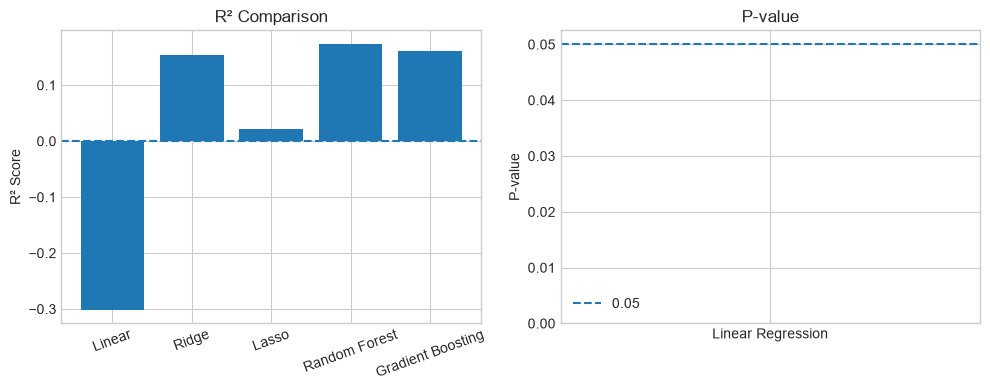

In [ ]:
models = ['Linear', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']
r2_scores = [-0.302, 0.154, 0.022, 0.174, 0.161]
p_values = [1.31e-08]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# R² plot
ax1.bar(models, r2_scores)
ax1.axhline(0, linestyle='--')
ax1.set_title('R² Comparison')
ax1.set_ylabel('R² Score')
ax1.tick_params(axis='x', rotation=20)

# P-value plot
ax2.bar(['Linear Regression'], p_values)
ax2.axhline(0.05, linestyle='--', label='0.05')
ax2.set_title('P-value')
ax2.set_ylabel('P-value')
ax2.legend()

plt.tight_layout()
plt.show()


Conclusion:
After comparing all regression models, Random Forest performed the best based on the R² score. Hyperparameter tuning further improved its R² from 0.171 to 0.222, showing that tuning enhanced the model's predictive performance.
The Linear Regression model had an overall p-value of 1.31 × 10⁻⁸, which is less than 0.05, indicating that the regression model is statistically significant.
Therefore, tuned Random Forest is selected as the best predictive model, while Linear Regression is statistically significant based on its p-value.

In [137]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/11.3 MB 4.8 MB/s eta 0:00:03
   --------- ------------------------------ 2.6/11.3 MB 5.6 MB/s eta 0:00:02
   ------------- -------------------------- 3.9/11.3 MB 5.9 MB/s eta 0:00:02
   ------------------- -------------------- 5.5/11.3 MB 6.3 MB/s eta 0:00:01
   ------------------------- -------------- 7.3/11.3 MB 6.9 MB/s eta 0:00:01
   ------------------------------- -------- 8.9/11.3 MB 7.0 MB/s eta 0:00:01
   -------------------------------------- - 11.0/11.3 MB 7.4 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 7.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
